<a href="https://colab.research.google.com/github/PercyTechX/PercyTechX/blob/main/MIA_YOLO_DEEPLEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi


Sun May 17 01:37:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q ultralytics roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.9/207.9 kB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 96.8 MB/s eta 0:00:00


In [3]:
import ultralytics
ultralytics.checks()


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.1/112.6 GB disk)


In [4]:
!pip check


ipython 7.34.0 requires jedi, which is not installed.


In [5]:
!yolo predict model=yolo11n.pt source='https://ultralytics.com/images/bus.jpg'


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 81.1ms
Speed: 8.7ms preprocess, 81.1ms inference, 48.0ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


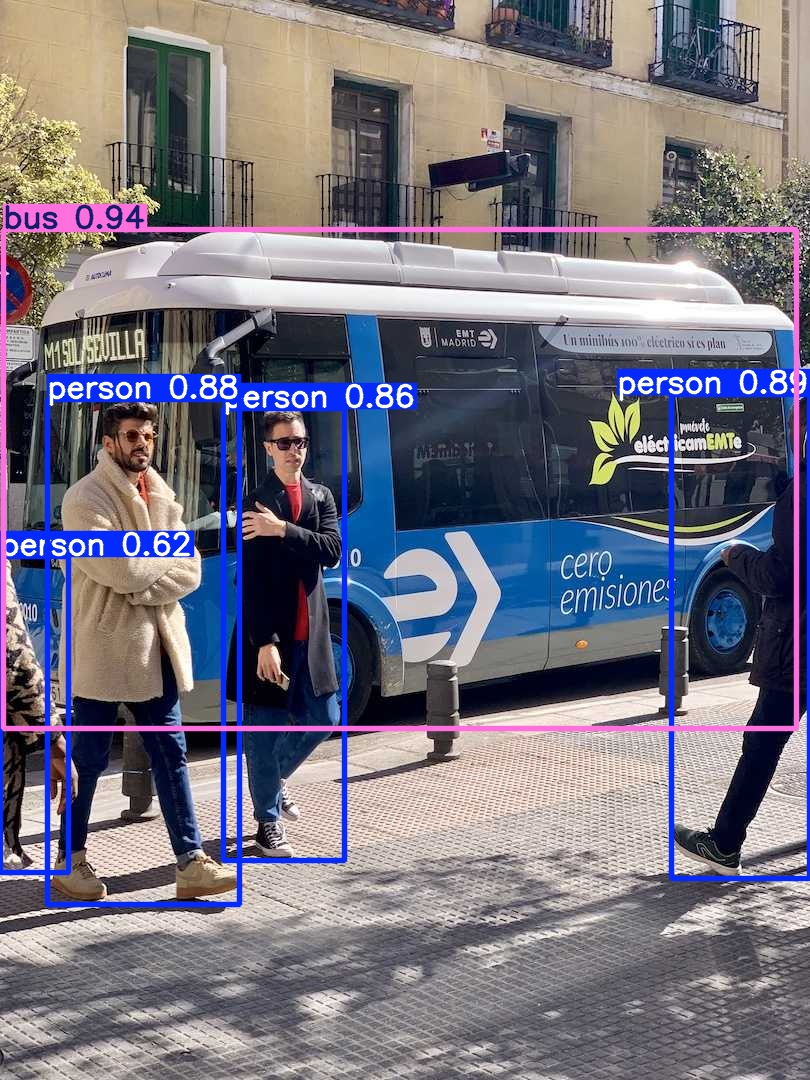

In [6]:
from IPython.display import Image
Image(filename='runs/detect/predict/bus.jpg', width=600)


In [7]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/decelera_landscape_min.mov -O sample.mp4


In [8]:
!ls -lh sample.mp4


-rw-r--r-- 1 root root 346K Jul 10  2024 sample.mp4


In [9]:
!yolo predict model=yolo11n.pt source='sample.mp4'


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs

video 1/1 (frame 1/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 49.8ms
video 1/1 (frame 2/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 10.8ms
video 1/1 (frame 3/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 10.4ms
video 1/1 (frame 4/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 10.1ms
video 1/1 (frame 5/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 9.4ms
video 1/1 (frame 6/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 10.4ms
video 1/1 (frame 7/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 12.0ms
video 1/1 (frame 8/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 10.5ms
video 1/1 (frame 9/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 9.7ms
video 1/1 (frame 10/11) /content/sample.mp4: 384x640 2 persons, 1 surfboard, 7.6ms
video

In [10]:
import glob, os
# Encuentra la carpeta más reciente de predict
out_dir = sorted(glob.glob('runs/detect/predict*'), key=os.path.getmtime)[-1]
print('Carpeta de salida:', out_dir)
!ls -lh {out_dir}


Carpeta de salida: runs/detect/predict-2
total 1.9M
-rw-r--r-- 1 root root 1.9M May 17 01:42 sample.avi


In [11]:
!ffmpeg -y -loglevel error -i {out_dir}/sample.avi -vcodec libx264 sample_out.mp4

from IPython.display import HTML
from base64 import b64encode
mp4 = open('sample_out.mp4', 'rb').read()
data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
HTML(f'<video width=600 controls><source src="{data_url}" type="video/mp4"></video>')


In [12]:
from getpass import getpass
from roboflow import Roboflow

api_key = getpass("Pega tu Roboflow API key y presiona Enter: ")

rf = Roboflow(api_key=api_key)
project = rf.workspace("tp2-bbjq4").project("peruvian-plate-detection-rbdtj")
version = project.version(2)
dataset = version.download("yolov11")

print("\n✅ Dataset descargado en:", dataset.location)


Pega tu Roboflow API key y presiona Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Peruvian-plate-detection-2 in yolov11:: 100%|██████████| 606/606 [00:00<00:00, 6130.06it/s]


✅ Dataset descargado en: /content/Peruvian-plate-detection-2


In [13]:
import os
print("Ruta del dataset:", dataset.location)
print("\nContenido:")
for item in sorted(os.listdir(dataset.location)):
    full = os.path.join(dataset.location, item)
    tag = "📁" if os.path.isdir(full) else "📄"
    print(f"  {tag} {item}")


Ruta del dataset: /content/Peruvian-plate-detection-2

Contenido:
  📄 README.dataset.txt
  📄 README.roboflow.txt
  📄 data.yaml
  📁 test
  📁 train
  📁 valid


In [14]:
for split in ["train", "valid", "test"]:
    p = os.path.join(dataset.location, split, "images")
    if os.path.isdir(p):
        print(f"{split}: {len(os.listdir(p))} imágenes")


train: 235 imágenes
valid: 41 imágenes
test: 21 imágenes


In [15]:
yaml_path = f"{dataset.location}/data.yaml"
print("Ruta:", yaml_path)
print("-" * 60)
!cat {yaml_path}


Ruta: /content/Peruvian-plate-detection-2/data.yaml
------------------------------------------------------------
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['car-plate']

roboflow:
  workspace: tp2-bbjq4
  project: peruvian-plate-detection-rbdtj
  version: 2
  license: MIT
  url: https://universe.roboflow.com/tp2-bbjq4/peruvian-plate-detection-rbdtj/dataset/2

In [16]:
import yaml

with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg["path"] = dataset.location                   # raíz absoluta del dataset
cfg["train"] = "train/images"                    # ahora relativas a "path"
cfg["val"]   = "valid/images"
cfg["test"]  = "test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)

print("✅ data.yaml actualizado:\n")
!cat {yaml_path}


✅ data.yaml actualizado:

train: train/images
val: valid/images
test: test/images
nc: 1
names:
- car-plate
roboflow:
  workspace: tp2-bbjq4
  project: peruvian-plate-detection-rbdtj
  version: 2
  license: MIT
  url: https://universe.roboflow.com/tp2-bbjq4/peruvian-plate-detection-rbdtj/dataset/2
path: /content/Peruvian-plate-detection-2


In [17]:
import os
for split in ["train", "valid", "test"]:
    imgs = len(os.listdir(f"{dataset.location}/{split}/images"))
    lbls = len(os.listdir(f"{dataset.location}/{split}/labels"))
    status = "✅" if imgs == lbls else "⚠️"
    print(f"{status} {split}: {imgs} imágenes / {lbls} labels")


✅ train: 235 imágenes / 235 labels
✅ valid: 41 imágenes / 41 labels
✅ test: 21 imágenes / 21 labels


In [18]:
!yolo detect train \
    data='/content/Peruvian-plate-detection-2/data.yaml' \
    model=yolo11n.pt \
    epochs=100 \
    imgsz=640 \
    name=placas_v1 \
    patience=20


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Peruvian-plate-detection-2/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=placas_v1, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mas

In [19]:
!yolo task=detect mode=predict \
    model=/content/runs/detect/placas_v1/weights/best.pt \
    source=/content/Peruvian-plate-detection-2/test/images \
    imgsz=640 \
    conf=0.25 \
    save=True \
    name=placas_test


Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs

image 1/21 /content/Peruvian-plate-detection-2/test/images/IMG-117402_png.rf.8a60e760bcc8fba74ae40b733b06278f.jpg: 640x640 1 car-plate, 11.4ms
image 2/21 /content/Peruvian-plate-detection-2/test/images/IMG-118887_png.rf.dedf3407d380d39616b56643c07114e1.jpg: 640x640 2 car-plates, 8.1ms
image 3/21 /content/Peruvian-plate-detection-2/test/images/IMG-19678_png.rf.f189d5ce1537ca94ff81cbb8ce60454c.jpg: 640x640 1 car-plate, 7.5ms
image 4/21 /content/Peruvian-plate-detection-2/test/images/IMG-22263_png.rf.06b3c435891d633e810ff32d8a3a9398.jpg: 640x640 1 car-plate, 7.4ms
image 5/21 /content/Peruvian-plate-detection-2/test/images/IMG-23528_png.rf.248abeb8da5a7b3c7c97950ad98c1fa3.jpg: 640x640 1 car-plate, 7.4ms
image 6/21 /content/Peruvian-plate-detection-2/test/images/IMG-2738_png.rf.fb11cbee12df4d17907f26c4cfa57db4.jpg: 640x640 1 c

Total de imágenes generadas: 21



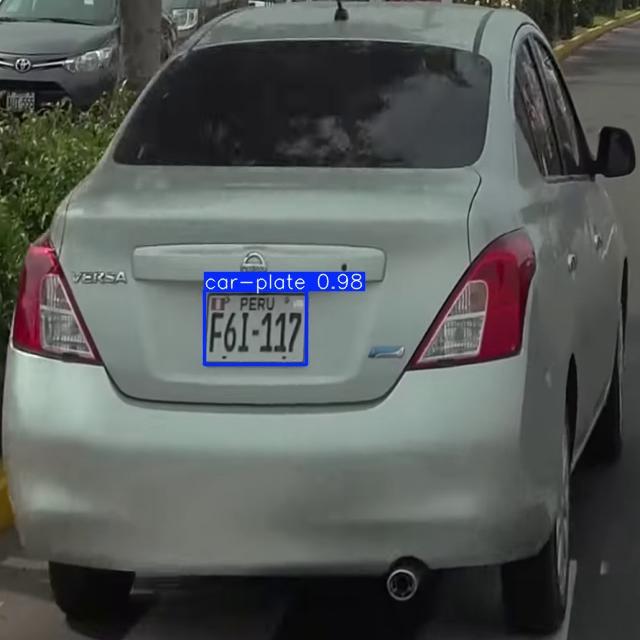

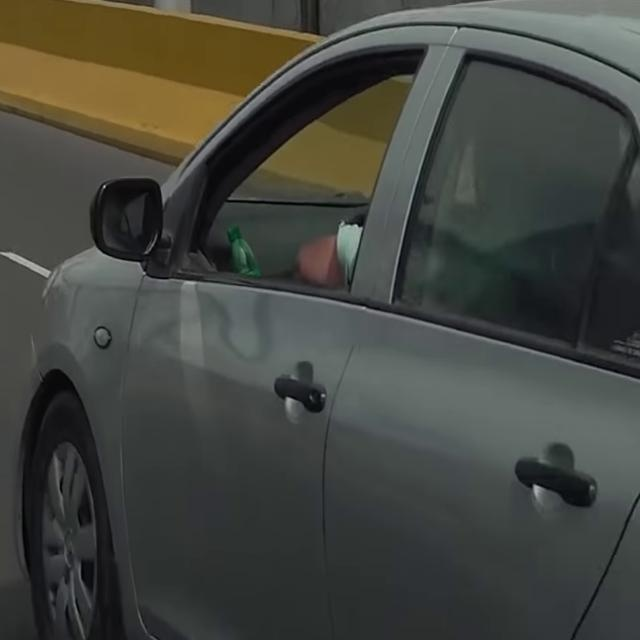

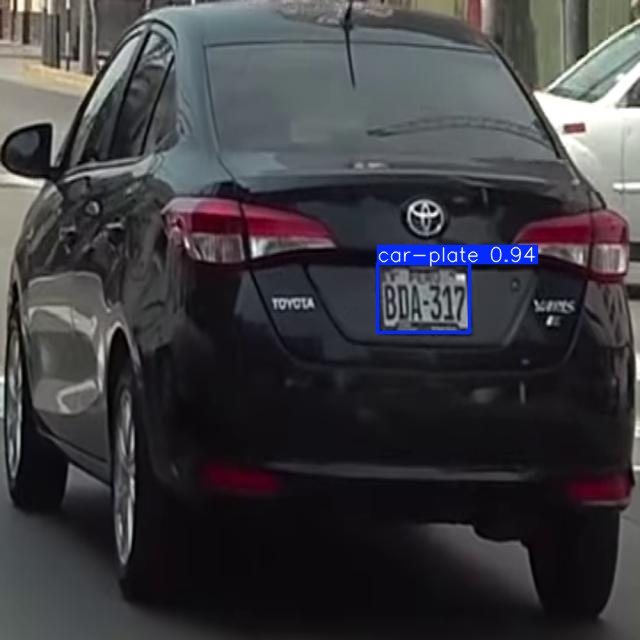

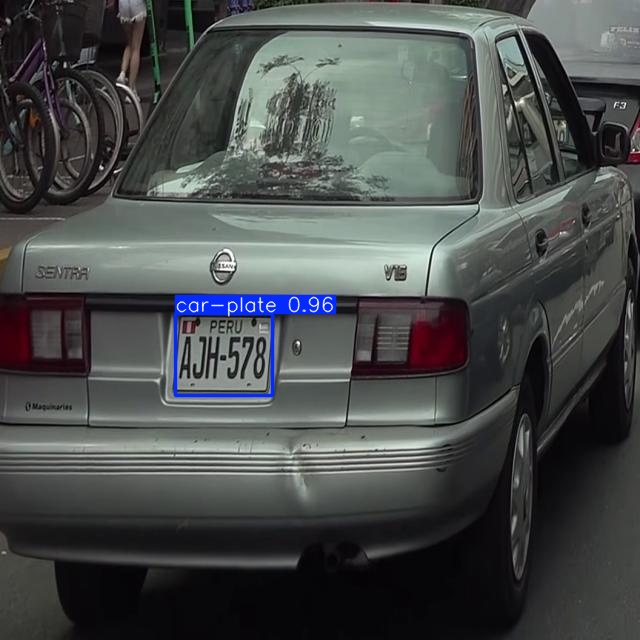

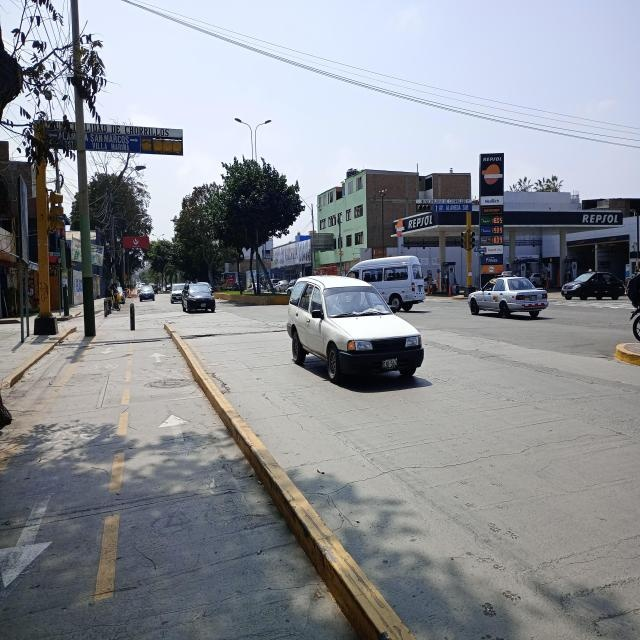

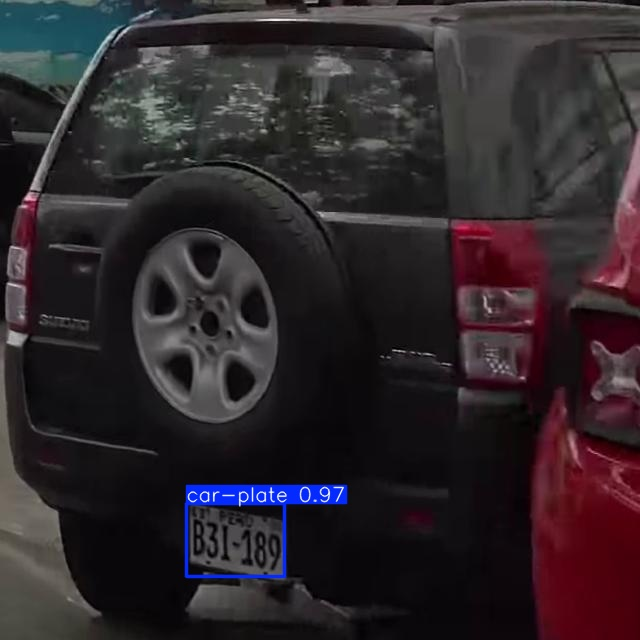

In [20]:
import glob, random
from IPython.display import Image, display, HTML

results_dir = "/content/runs/detect/placas_test"
images = sorted(glob.glob(f"{results_dir}/*.jpg"))
print(f"Total de imágenes generadas: {len(images)}\n")

# Muestra 6 al azar
sample = random.sample(images, min(6, len(images)))
for img_path in sample:
    display(HTML(f"<h4>{img_path.split('/')[-1]}</h4>"))
    display(Image(filename=img_path, width=500))


In [21]:
import glob
match = glob.glob("/content/Peruvian-plate-detection-2/test/images/img-32229*")
print("Coincidencias:", match)

if match:
    !yolo task=detect mode=predict \
        model=/content/runs/detect/placas_v1/weights/best.pt \
        source='{match[0]}' \
        imgsz=640 \
        name=placas_pdf_demo

    from IPython.display import Image
    out = glob.glob("/content/runs/detect/placas_pdf_demo/*.jpg")[0]
    Image(filename=out, width=600)


Coincidencias: ['/content/Peruvian-plate-detection-2/test/images/img-32229_png.rf.e9c1cad13b7e43c264aec28fd675bc5a.jpg']
Ultralytics 8.4.51 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs

image 1/1 /content/Peruvian-plate-detection-2/test/images/img-32229_png.rf.e9c1cad13b7e43c264aec28fd675bc5a.jpg: 640x640 1 car-plate, 11.4ms
Speed: 2.8ms preprocess, 11.4ms inference, 16.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/placas_pdf_demo
💡 Learn more at https://docs.ultralytics.com/modes/predict


In [22]:
from google.colab import files
files.download('/content/runs/detect/placas_v1/weights/best.pt')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== results.png ===


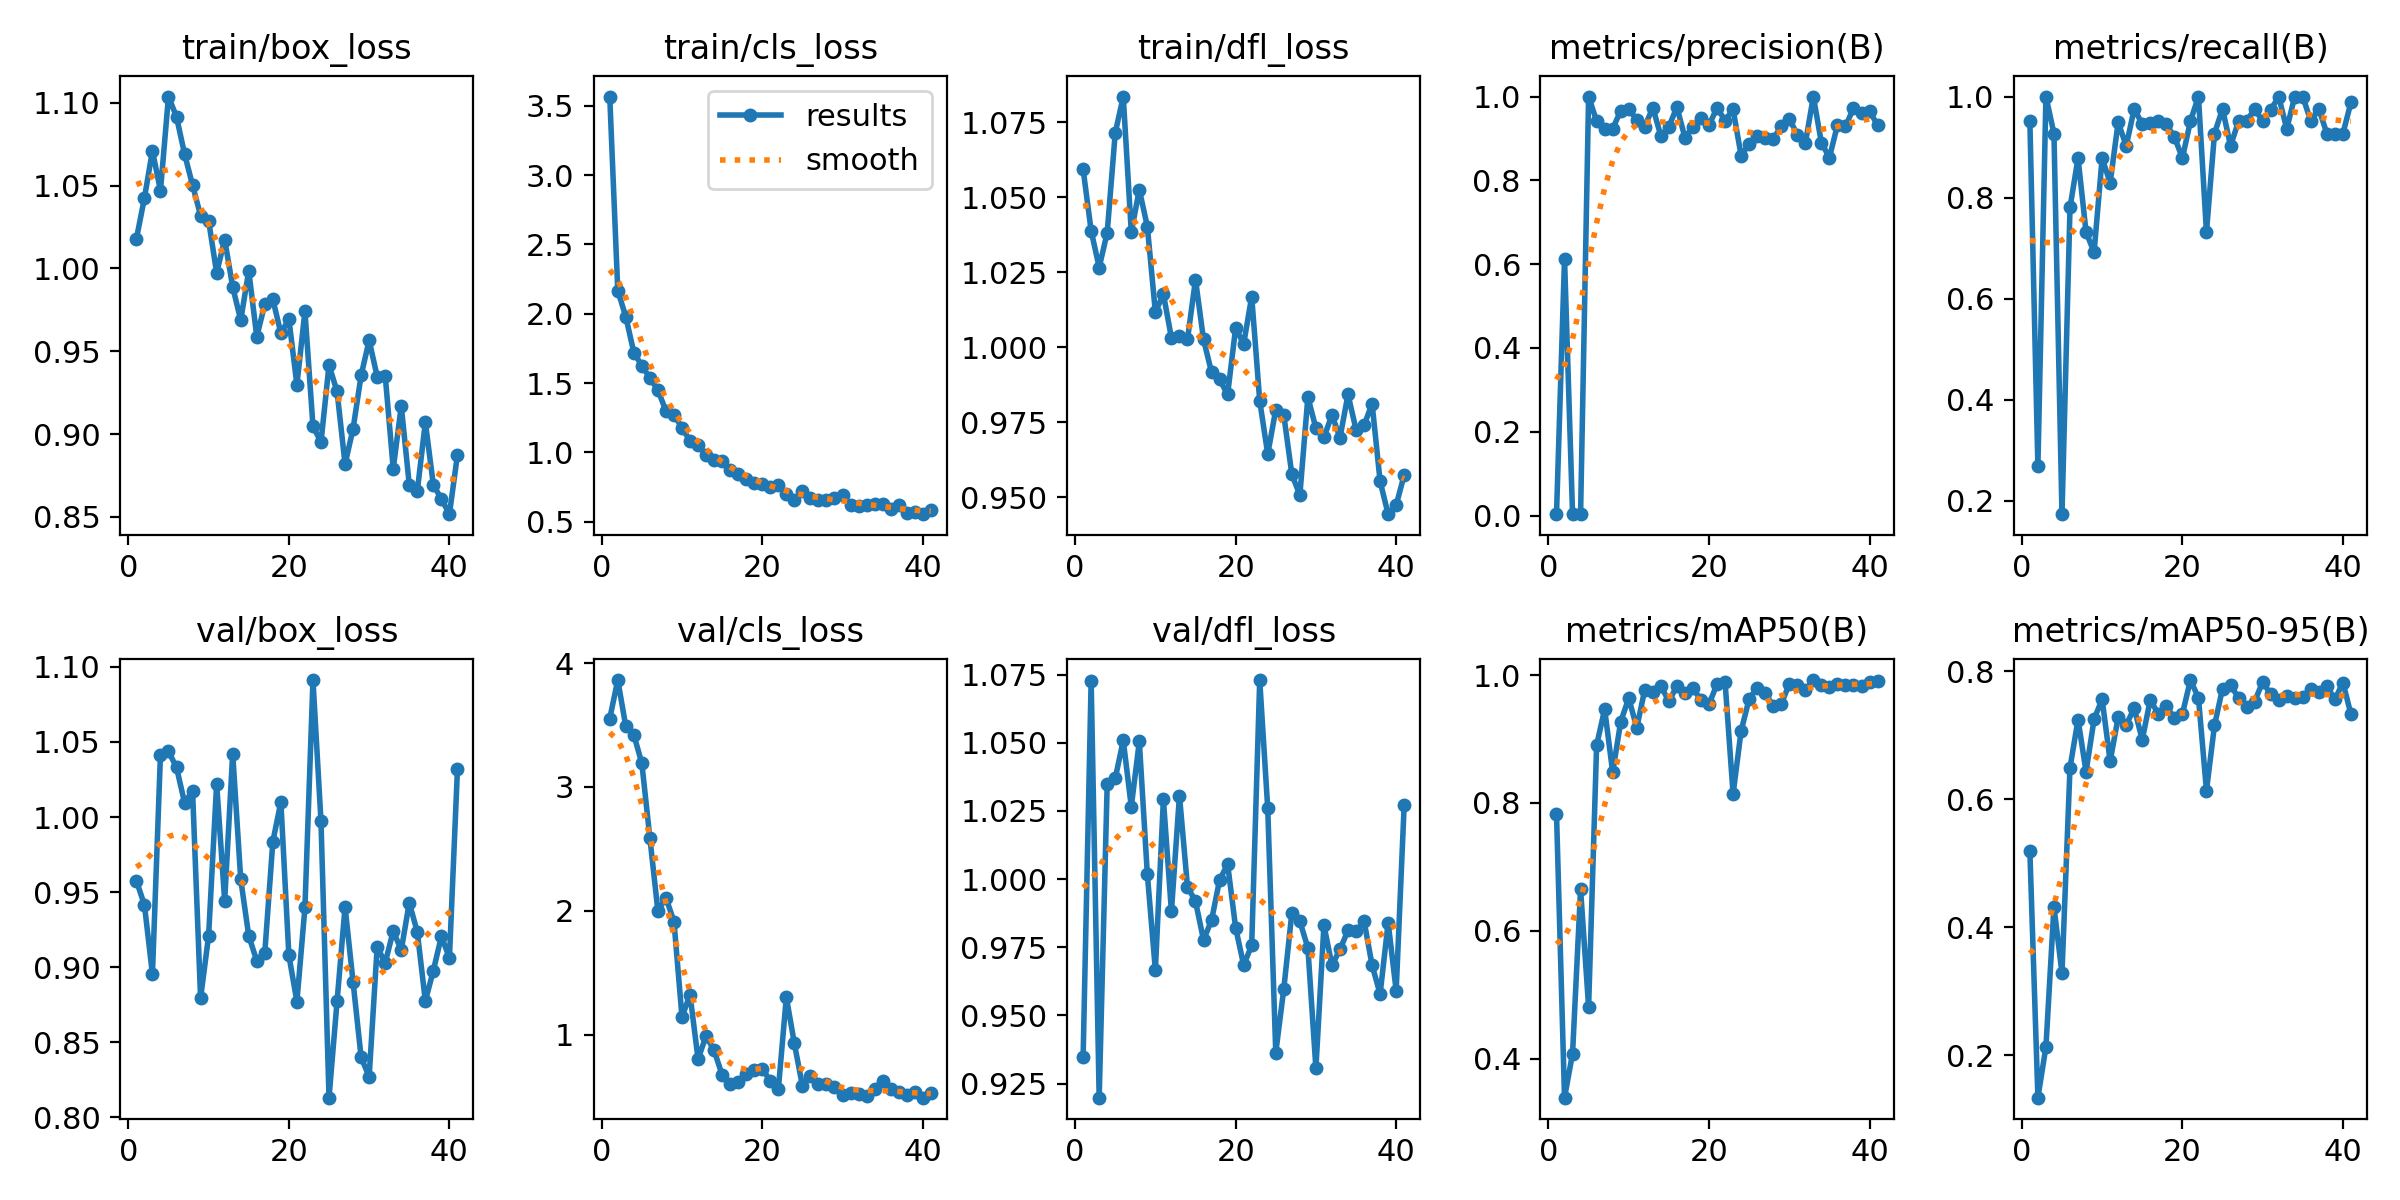


=== confusion_matrix.png ===


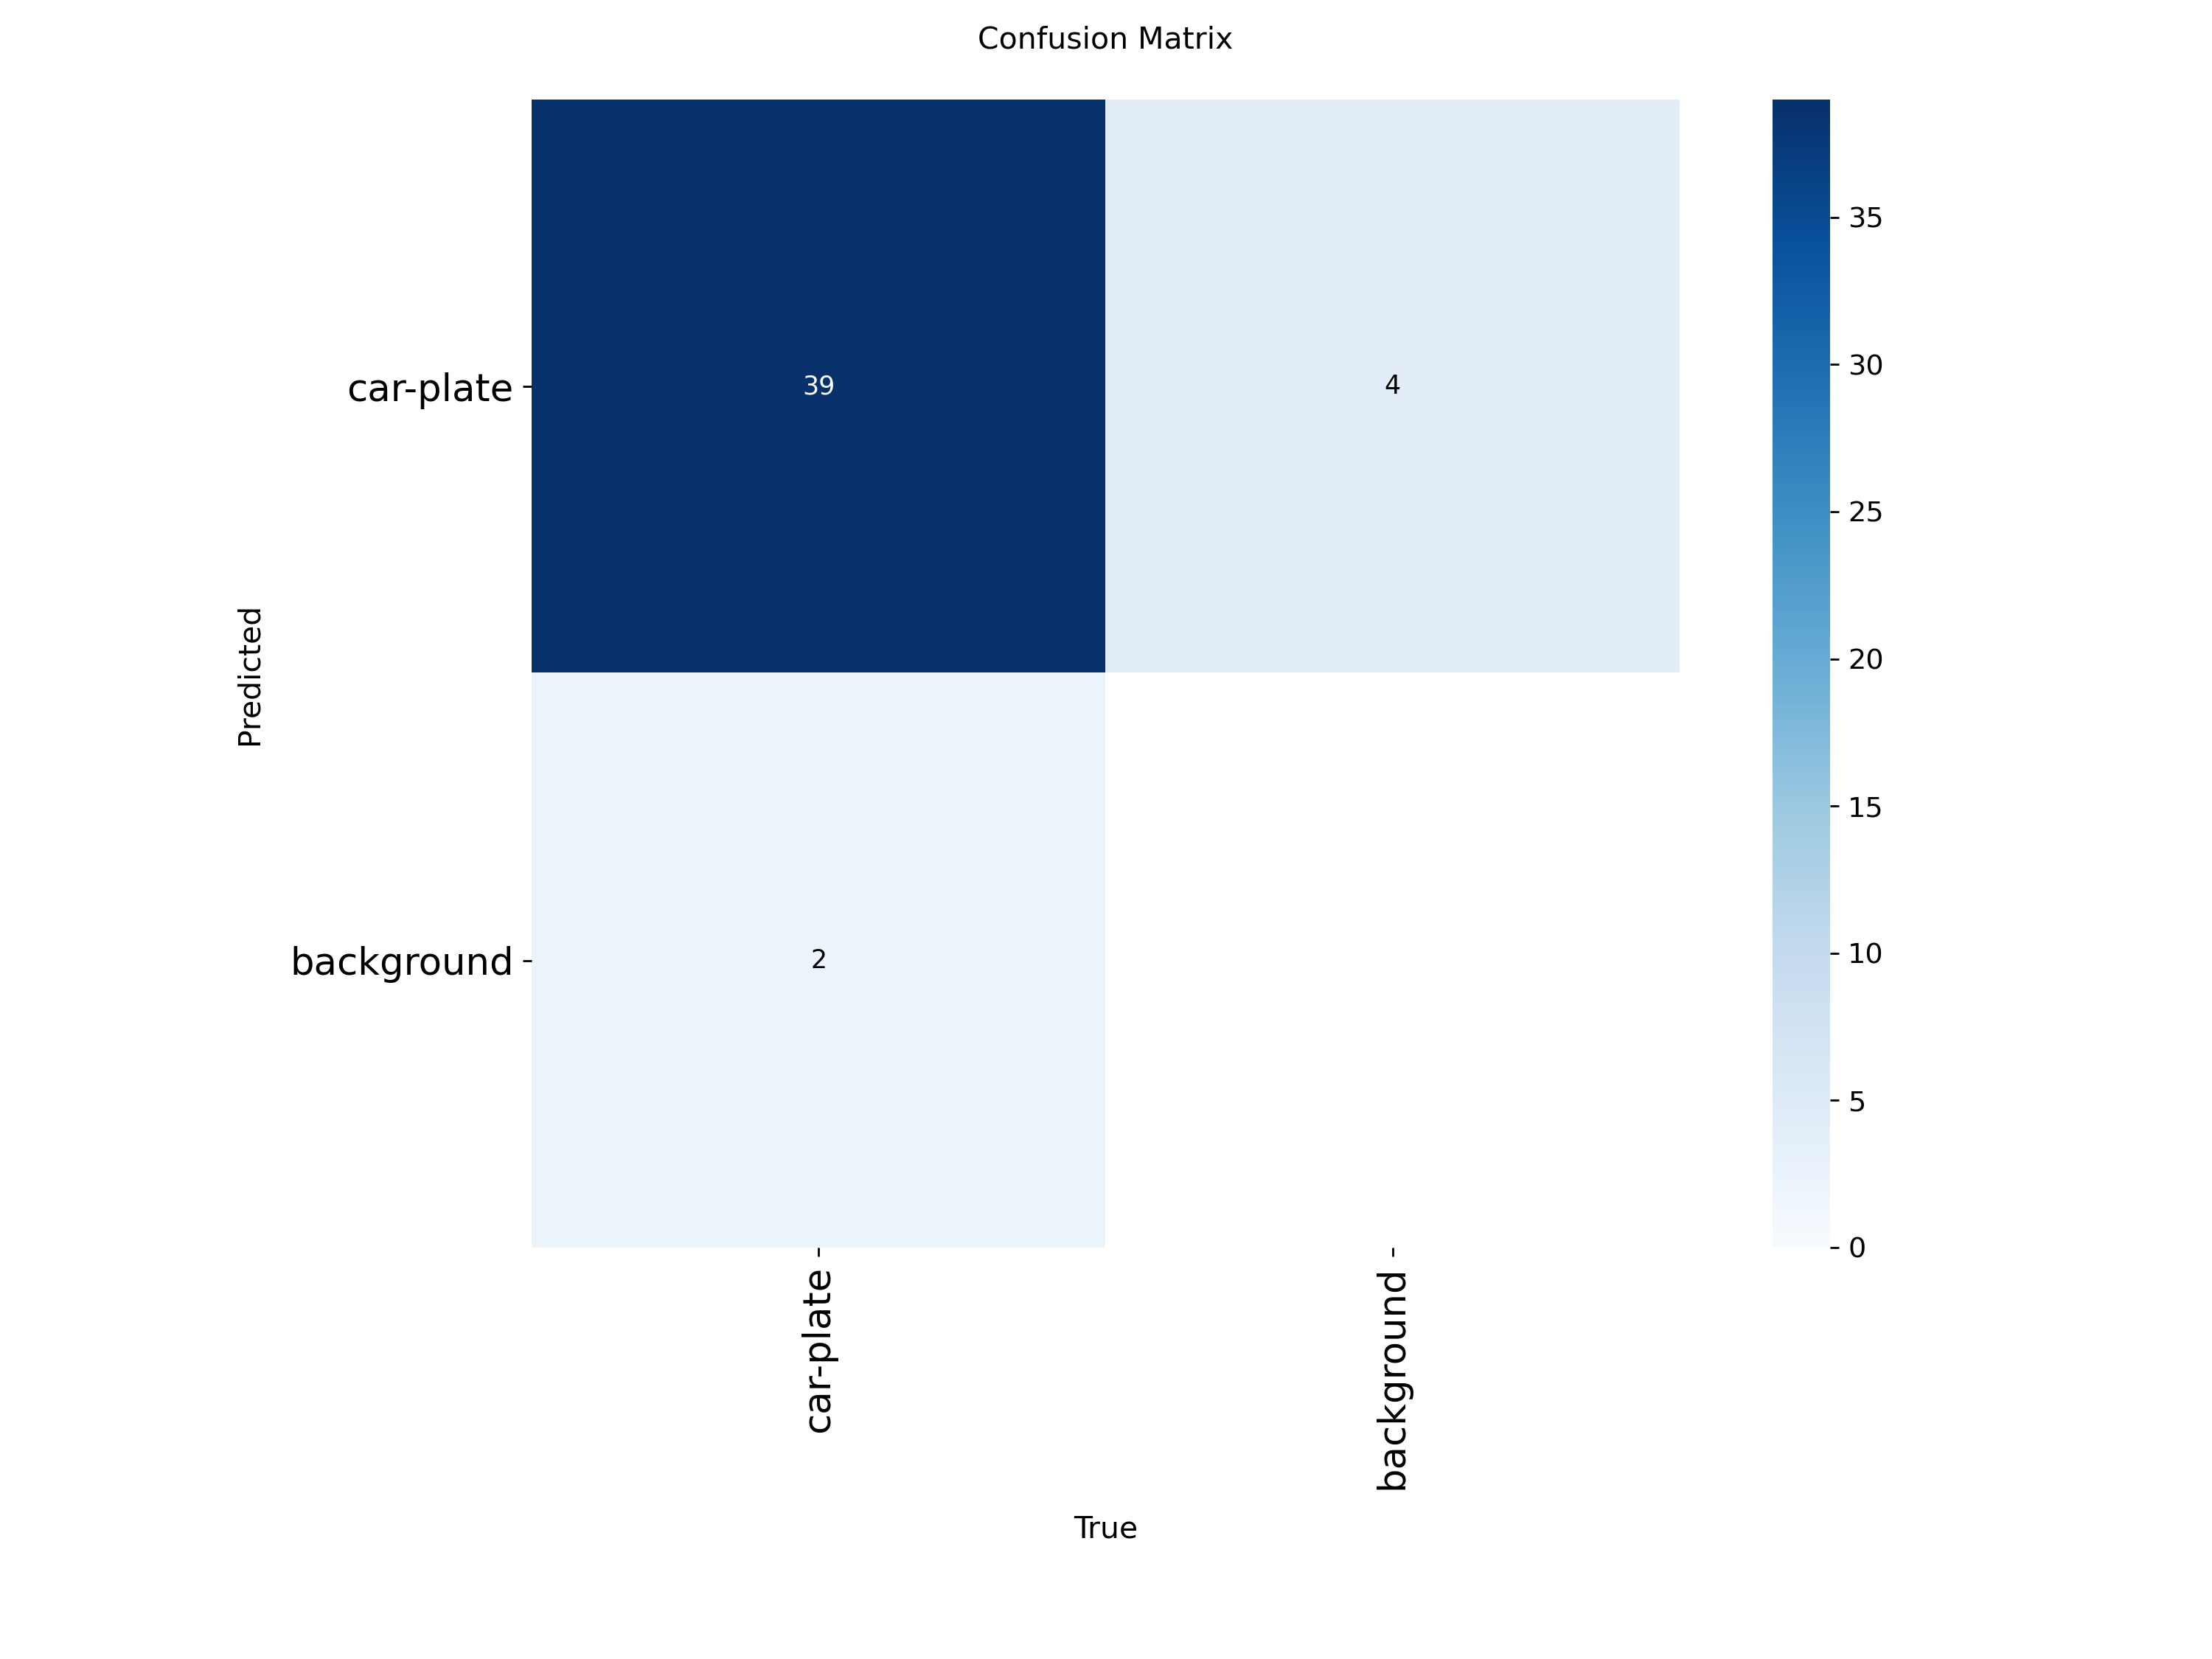


=== val_batch0_pred.jpg ===


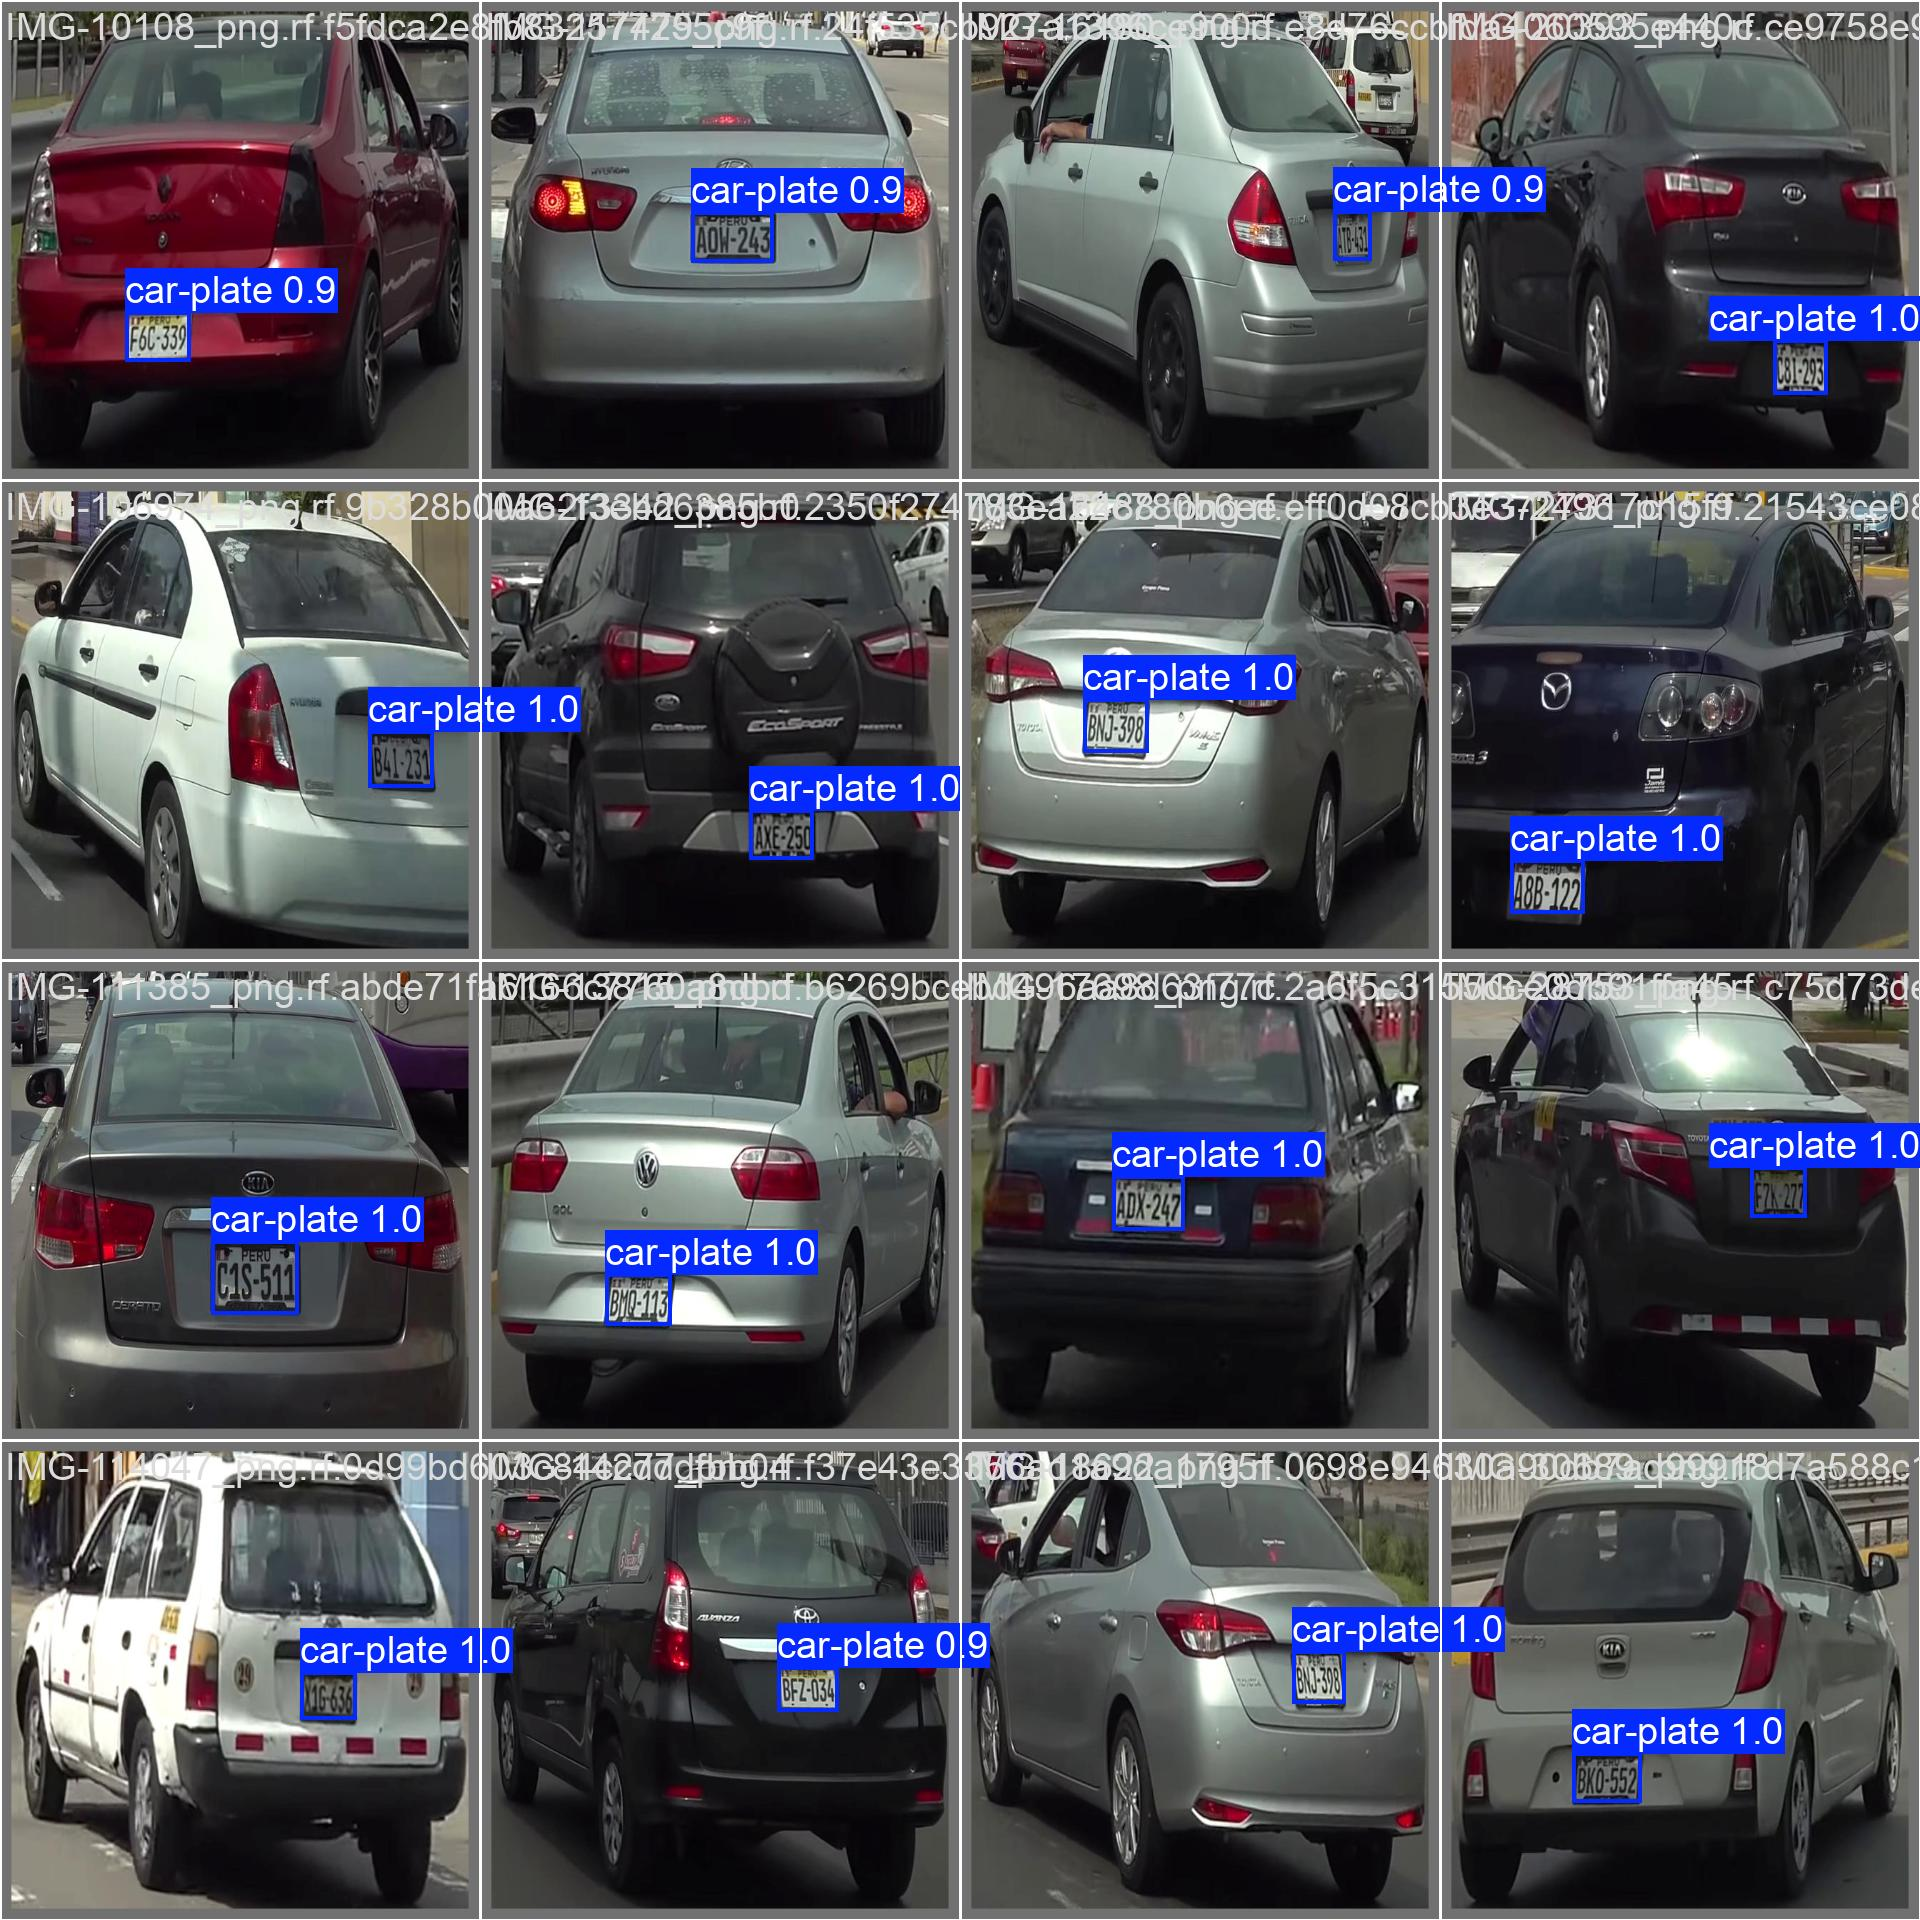

In [23]:
from IPython.display import Image, display
for plot in ['results.png', 'confusion_matrix.png', 'val_batch0_pred.jpg']:
    path = f'/content/runs/detect/placas_v1/{plot}'
    if __import__('os').path.exists(path):
        print(f"\n=== {plot} ===")
        display(Image(filename=path, width=700))


In [24]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os
dest_dir = '/content/drive/MyDrive/placas_peruanas'
os.makedirs(dest_dir, exist_ok=True)

# Copia el modelo entrenado y los gráficos
shutil.copy('/content/runs/detect/placas_v1/weights/best.pt', dest_dir)
shutil.copy('/content/runs/detect/placas_v1/weights/last.pt', dest_dir)
shutil.copy('/content/runs/detect/placas_v1/results.png', dest_dir)
shutil.copy('/content/runs/detect/placas_v1/confusion_matrix.png', dest_dir)

print("✅ Guardado en Drive:")
!ls -lh {dest_dir}


Mounted at /content/drive
✅ Guardado en Drive:
total 11M
-rw------- 1 root root 5.3M May 17 02:04 best.pt
-rw------- 1 root root  93K May 17 02:04 confusion_matrix.png
-rw------- 1 root root 5.3M May 17 02:04 last.pt
-rw------- 1 root root 347K May 17 02:04 results.png
